In [2]:
print("AI Phishing Email Detector")
print("Workspace is ready!")

AI Phishing Email Detector
Workspace is ready!


In [3]:
import pandas as pd

print("Pandas imported successfully!")

Pandas imported successfully!


In [4]:
from google.colab import files

uploaded = files.upload()

Saving Phishing_validation_emails.csv to Phishing_validation_emails.csv


In [5]:

import pandas as pd

# Load the uploaded dataset
df = pd.read_csv("Phishing_validation_emails.csv")

# Display basic information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Display the first 5 rows
display(df.head())


Dataset loaded successfully!
Dataset shape: (2000, 2)


,Email Text,Email Type
0,"Dear Jordan, your subscription has been succes...",Safe Email
1,"Dear Casey, thank you for your purchase. Your ...",Safe Email
2,Congratulations! You've won a $3000 gift card....,Phishing Email
3,You have a new secure message from your bank. ...,Phishing Email
4,Your package delivery is pending. Please provi...,Phishing Email


In [6]:

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values per column:")
print(df.isnull().sum())


Column names:
['Email Text', 'Email Type']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Email Text  2000 non-null   object
 1   Email Type  2000 non-null   object
dtypes: object(2)
memory usage: 31.4+ KB

Missing values per column:
Email Text    0
Email Type    0
dtype: int64


In [7]:

# 1. Check for duplicate emails
print("Duplicate rows:", df.duplicated().sum())

# 2. Check the class distribution
print("\nEmail type distribution:")
print(df["Email Type"].value_counts())

# 3. Check the percentage of each class
print("\nClass percentages:")
print(
    (df["Email Type"].value_counts(normalize=True) * 100)
    .round(2)
    .astype(str) + "%"
)

# 4. Check whether any labels are missing
print("\nMissing labels:", df["Email Type"].isnull().sum())

# 5. Check the unique labels
print("\nUnique labels:")
print(df["Email Type"].unique())


Duplicate rows: 1900

Email type distribution:
Email Type
Safe Email        1000
Phishing Email    1000
Name: count, dtype: int64

Class percentages:
Email Type
Safe Email        50.0%
Phishing Email    50.0%
Name: proportion, dtype: object

Missing labels: 0

Unique labels:
['Safe Email' 'Phishing Email']


In [8]:

# Count unique email texts
print("Unique email texts:", df["Email Text"].nunique())

# Show how often each email appears
print("\nMost repeated emails:")
display(
    df["Email Text"]
    .value_counts()
    .head(10)
    .to_frame("Occurrences")
)

# Check whether the same text has conflicting labels
label_counts = df.groupby("Email Text")["Email Type"].nunique()

print(
    "\nEmail texts with conflicting labels:",
    (label_counts > 1).sum()
)

# Display a sample of duplicate records
print("\nSample duplicate records:")
display(
    df[df.duplicated(keep=False)]
    .sort_values("Email Text")
    .head(10)
)


Unique email texts: 100

Most repeated emails:


,Occurrences
Email Text,
Your subscription is about to expire. Renew now to continue enjoying our services.,112
Your payment has been declined. Update your billing information to continue using our service.,110
You have a new secure message from your bank. Click here to read it.,103
Your invoice is attached. Please review and pay promptly to avoid penalties.,103
Please find attached the minutes from our last meeting. Let me know if you have any questions.,97
Alert: Unusual login attempt detected. Verify your account by clicking here.,95
Your package delivery is pending. Please provide your personal information to confirm delivery.,93
We noticed some unusual activity in your account. Log in to review recent transactions.,93
Important: Update your email account settings to avoid service interruption.,89



Email texts with conflicting labels: 0

Sample duplicate records:


,Email Text,Email Type
1166,Alert: Unusual login attempt detected. Verify ...,Phishing Email
1599,Alert: Unusual login attempt detected. Verify ...,Phishing Email
1296,Alert: Unusual login attempt detected. Verify ...,Phishing Email
120,Alert: Unusual login attempt detected. Verify ...,Phishing Email
119,Alert: Unusual login attempt detected. Verify ...,Phishing Email
1298,Alert: Unusual login attempt detected. Verify ...,Phishing Email
1108,Alert: Unusual login attempt detected. Verify ...,Phishing Email
1580,Alert: Unusual login attempt detected. Verify ...,Phishing Email
929,Alert: Unusual login attempt detected. Verify ...,Phishing Email
113,Alert: Unusual login attempt detected. Verify ...,Phishing Email


In [9]:

# Keep only unique email-text and label combinations
df_clean = df.drop_duplicates(
    subset=["Email Text", "Email Type"]
).copy()

# Reset the row numbering
df_clean = df_clean.reset_index(drop=True)

print("Original rows:", len(df))
print("Rows after removing duplicates:", len(df_clean))
print("Unique email texts:", df_clean["Email Text"].nunique())

print("\nClass distribution after cleaning:")
print(df_clean["Email Type"].value_counts())

# Save the cleaned dataset
df_clean.to_csv("cleaned_phishing_emails.csv", index=False)

print("\nCleaned dataset saved successfully!")


Original rows: 2000
Rows after removing duplicates: 100
Unique email texts: 100

Class distribution after cleaning:
Email Type
Safe Email        77
Phishing Email    23
Name: count, dtype: int64

Cleaned dataset saved successfully!


In [10]:

print("Cleaned dataset shape:", df_clean.shape)

print("\nClass distribution:")
print(df_clean["Email Type"].value_counts())

print("\nClass percentages:")
print(
    (df_clean["Email Type"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nRemaining duplicate rows:", df_clean.duplicated().sum())


Cleaned dataset shape: (100, 2)

Class distribution:
Email Type
Safe Email        77
Phishing Email    23
Name: count, dtype: int64

Class percentages:
Email Type
Safe Email        77.0
Phishing Email    23.0
Name: proportion, dtype: float64

Remaining duplicate rows: 0


In [11]:

import pandas as pd

dataset_url = (
    "https://huggingface.co/datasets/"
    "zefang-liu/phishing-email-dataset/"
    "resolve/main/Phishing_Email.csv"
)

large_df = pd.read_csv(dataset_url)

print("Dataset loaded successfully!")
print("Dataset shape:", large_df.shape)

print("\nColumn names:")
print(large_df.columns.tolist())

print("\nFirst five rows:")
display(large_df.head())

print("\nMissing values:")
print(large_df.isnull().sum())


Dataset loaded successfully!
Dataset shape: (18650, 3)

Column names:
['Unnamed: 0', 'Email Text', 'Email Type']

First five rows:


,Unnamed: 0,Email Text,Email Type
0,0,"re : 6 . 1100 , disc : uniformitarianism , re ...",Safe Email
1,1,the other side of * galicismos * * galicismo *...,Safe Email
2,2,re : equistar deal tickets are you still avail...,Safe Email
3,3,\nHello I am your hot lil horny toy.\n I am...,Phishing Email
4,4,software at incredibly low prices ( 86 % lower...,Phishing Email



Missing values:
Unnamed: 0     0
Email Text    16
Email Type     0
dtype: int64


In [12]:

# Inspect the email labels
print("Email type distribution:")
print(large_df["Email Type"].value_counts())

print("\nClass percentages:")
print(
    (large_df["Email Type"].value_counts(normalize=True) * 100)
    .round(2)
)

# Check duplicate rows
print("\nExact duplicate rows:", large_df.duplicated().sum())

# Check duplicate email texts
print(
    "Duplicate email texts:",
    large_df["Email Text"].dropna().duplicated().sum()
)

# Inspect missing email text
print("\nMissing email texts:", large_df["Email Text"].isna().sum())

# Inspect unique labels
print("\nUnique labels:", large_df["Email Type"].unique())


Email type distribution:
Email Type
Safe Email        11322
Phishing Email     7328
Name: count, dtype: int64

Class percentages:
Email Type
Safe Email        60.71
Phishing Email    39.29
Name: proportion, dtype: float64

Exact duplicate rows: 0
Duplicate email texts: 1097

Missing email texts: 16

Unique labels: ['Safe Email' 'Phishing Email']


In [13]:

# Keep only the columns needed for the model
model_df = large_df[["Email Text", "Email Type"]].copy()

# Remove rows without email text
model_df = model_df.dropna(subset=["Email Text"])

# Remove blank email messages
model_df["Email Text"] = model_df["Email Text"].astype(str).str.strip()
model_df = model_df[model_df["Email Text"] != ""]

# Remove exact duplicate messages
model_df = model_df.drop_duplicates(
    subset=["Email Text"],
    keep="first"
).reset_index(drop=True)

# Verify the cleaned data
print("Original dataset rows:", len(large_df))
print("Cleaned dataset rows:", len(model_df))
print("Remaining missing values:", model_df.isnull().sum().sum())
print("Duplicate email texts:", model_df["Email Text"].duplicated().sum())

print("\nClass distribution:")
print(model_df["Email Type"].value_counts())

# Save the cleaned dataset
model_df.to_csv("cleaned_phishing_dataset.csv", index=False)

print("\nCleaned dataset saved successfully!")


Original dataset rows: 18650
Cleaned dataset rows: 17522
Remaining missing values: 0
Duplicate email texts: 0

Class distribution:
Email Type
Safe Email        10978
Phishing Email     6544
Name: count, dtype: int64

Cleaned dataset saved successfully!


In [14]:

# Check whether identical email texts have different labels
label_counts = (
    large_df.dropna(subset=["Email Text", "Email Type"])
    .groupby("Email Text")["Email Type"]
    .nunique()
)

conflicts = label_counts[label_counts > 1]

print("Email texts with conflicting labels:", len(conflicts))

if len(conflicts) > 0:
    print("\nExamples of conflicting labels:")
    display(
        large_df[large_df["Email Text"].isin(conflicts.index)]
        [["Email Text", "Email Type"]]
        .sort_values("Email Text")
        .head(10)
    )
else:
    print("No conflicting labels found.")


Email texts with conflicting labels: 1

Examples of conflicting labels:


,Email Text,Email Type
54,empty,Phishing Email
12606,empty,Phishing Email
12599,empty,Phishing Email
12592,empty,Safe Email
12584,empty,Safe Email
12571,empty,Phishing Email
12524,empty,Safe Email
12479,empty,Phishing Email
12459,empty,Safe Email
12444,empty,Safe Email


In [15]:

# Remove placeholder text that is not a real email
model_df["Email Text"] = model_df["Email Text"].str.strip()

invalid_texts = ["", "empty", "nan", "none", "null"]

model_df = model_df[
    ~model_df["Email Text"].str.lower().isin(invalid_texts)
].copy()

# Reset the index
model_df = model_df.reset_index(drop=True)

print("Final dataset shape:", model_df.shape)
print("\nClass distribution:")
print(model_df["Email Type"].value_counts())

print("\nMissing values:", model_df.isnull().sum().sum())
print("Duplicate email texts:", model_df["Email Text"].duplicated().sum())

# Save the final dataset
model_df.to_csv("final_phishing_dataset.csv", index=False)

print("\nFinal dataset saved successfully!")


Final dataset shape: (17521, 2)

Class distribution:
Email Type
Safe Email        10978
Phishing Email     6543
Name: count, dtype: int64

Missing values: 0
Duplicate email texts: 0

Final dataset saved successfully!


In [16]:

from sklearn.model_selection import train_test_split

# Input text and target labels
X = model_df["Email Text"]
y = model_df["Email Type"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training emails:", len(X_train))
print("Testing emails:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())


Training emails: 14016
Testing emails: 3505

Training label distribution:
Email Type
Safe Email        8782
Phishing Email    5234
Name: count, dtype: int64

Testing label distribution:
Email Type
Safe Email        2196
Phishing Email    1309
Name: count, dtype: int64


In [17]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Build the machine-learning pipeline
model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            stop_words="english",
            max_features=20000,
            ngram_range=(1, 2),
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


Model Accuracy: 98.32%

Classification Report:
                precision    recall  f1-score   support

Phishing Email       0.98      0.97      0.98      1309
    Safe Email       0.98      0.99      0.99      2196

      accuracy                           0.98      3505
     macro avg       0.98      0.98      0.98      3505
  weighted avg       0.98      0.98      0.98      3505

Confusion Matrix:
[[2174   22]
 [  37 1272]]


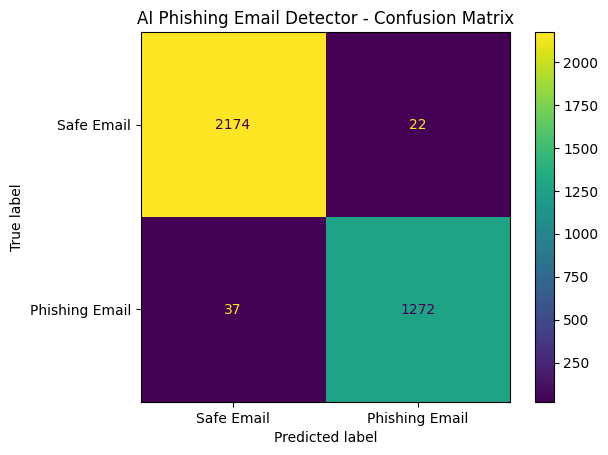

In [18]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict labels for unseen test emails
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.2%}")

# Detailed evaluation
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Safe Email", "Phishing Email"]
)

print("Confusion Matrix:")
print(cm)

# Visualize the results
display_plot = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Safe Email", "Phishing Email"]
)

display_plot.plot()
plt.title("AI Phishing Email Detector - Confusion Matrix")
plt.show()


In [19]:

def check_email(email_text):
    prediction = model.predict([email_text])[0]
    probabilities = model.predict_proba([email_text])[0]

    classes = model.named_steps["classifier"].classes_
    probability_by_class = dict(zip(classes, probabilities))

    print("Prediction:", prediction)
    print(
        "Phishing score:",
        f"{probability_by_class['Phishing Email']:.2%}"
    )

    if prediction == "Phishing Email":
        print("Advice: Do not click links or share sensitive information.")
    else:
        print("Advice: No phishing pattern was detected confidently enough.")
        print("Still verify the sender and any links before taking action.")

# Test with a simulated suspicious message
check_email(
    "URGENT! Your bank account will be blocked. "
    "Click here immediately to verify your password."
)


Prediction: Phishing Email
Phishing score: 91.33%
Advice: Do not click links or share sensitive information.


In [20]:
import joblib

joblib.dump(model, "phishing_detector_model.joblib")

print("Model saved successfully!")

Model saved successfully!


In [21]:
from google.colab import files

files.download("phishing_detector_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
def analyze_email(email_text):
    if not email_text or not email_text.strip():
        return {
            "prediction": "No email provided",
            "phishing_score": None,
            "advice": "Please enter an email to analyze."
        }

    prediction = model.predict([email_text])[0]

    probabilities = model.predict_proba([email_text])[0]
    classes = model.named_steps["classifier"].classes_

    probability_by_class = dict(zip(classes, probabilities))
    phishing_score = probability_by_class["Phishing Email"] * 100

    if prediction == "Phishing Email":
        advice = (
            "Warning: This email resembles phishing messages. "
            "Do not click links or share passwords or OTPs."
        )
    else:
        advice = (
            "No strong phishing pattern detected. "
            "Still verify the sender and links before taking action."
        )

    return {
        "prediction": prediction,
        "phishing_score": round(phishing_score, 2),
        "advice": advice
    }


print("Email analyzer is ready!")

Email analyzer is ready!


In [23]:
sample_email = """
URGENT! Your bank account will be blocked today.
Click here immediately to verify your password.
"""

result = analyze_email(sample_email)

for key, value in result.items():
    print(f"{key.replace('_', ' ').title()}: {value}")

Prediction: Phishing Email
Phishing Score: 91.15
Advice: Warning: This email resembles phishing messages. Do not click links or share passwords or OTPs.


In [24]:
!pip -q install ipywidgets

In [25]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Email input area
email_input = widgets.Textarea(
    value="",
    placeholder="Paste the email text you want to analyze...",
    description="Email:",
    layout=widgets.Layout(width="100%", height="180px"),
    style={"description_width": "initial"}
)

# Analyze button
analyze_button = widgets.Button(
    description="Analyze Email",
    button_style="primary",
    icon="search"
)

# Output area
output = widgets.Output()

def on_analyze_click(button):
    with output:
        clear_output(wait=True)

        email_text = email_input.value

        if not email_text.strip():
            print("Please paste an email before analyzing.")
            return

        result = analyze_email(email_text)

        print("AI PHISHING EMAIL DETECTOR")
        print("-" * 35)
        print("Prediction:", result["prediction"])

        if result["phishing_score"] is not None:
            print(
                "Estimated Phishing Score:",
                f'{result["phishing_score"]:.2f}%'
            )

        print("\nSafety Advice:")
        print(result["advice"])

analyze_button.on_click(on_analyze_click)

display(
    widgets.VBox([
        widgets.HTML("<h2>AI Phishing Email Detector</h2>"),
        widgets.HTML(
            "<p>Paste an email below to check for phishing patterns.</p>"
        ),
        email_input,
        analyze_button,
        output
    ])
)

In [26]:
import pandas as pd

def analyze_multiple_emails(email_list):
    results = []

    for email_text in email_list:
        result = analyze_email(email_text)

        results.append({
            "Email Preview": email_text[:80].replace("\n", " "),
            "Prediction": result["prediction"],
            "Phishing Score (%)": result["phishing_score"],
            "Safety Advice": result["advice"]
        })

    return pd.DataFrame(results)


sample_emails = [
    "URGENT: Click here to verify your bank password immediately.",
    "Hi team, our meeting is scheduled for tomorrow at 10 AM.",
    "Congratulations! You won a prize. Send your OTP to claim it.",
    "Please find the project report attached for your review."
]

results_df = analyze_multiple_emails(sample_emails)

display(results_df)

,Email Preview,Prediction,Phishing Score (%),Safety Advice
0,URGENT: Click here to verify your bank passwor...,Phishing Email,89.97,Warning: This email resembles phishing message...
1,"Hi team, our meeting is scheduled for tomorrow...",Safe Email,10.72,No strong phishing pattern detected. Still ver...
2,Congratulations! You won a prize. Send your OT...,Phishing Email,54.82,Warning: This email resembles phishing message...
3,Please find the project report attached for yo...,Safe Email,4.98,No strong phishing pattern detected. Still ver...


,Metric,Score (%)
0,Accuracy,98.32
1,Phishing Precision,98.30
2,Phishing Recall,97.17
3,Phishing F1-Score,97.73


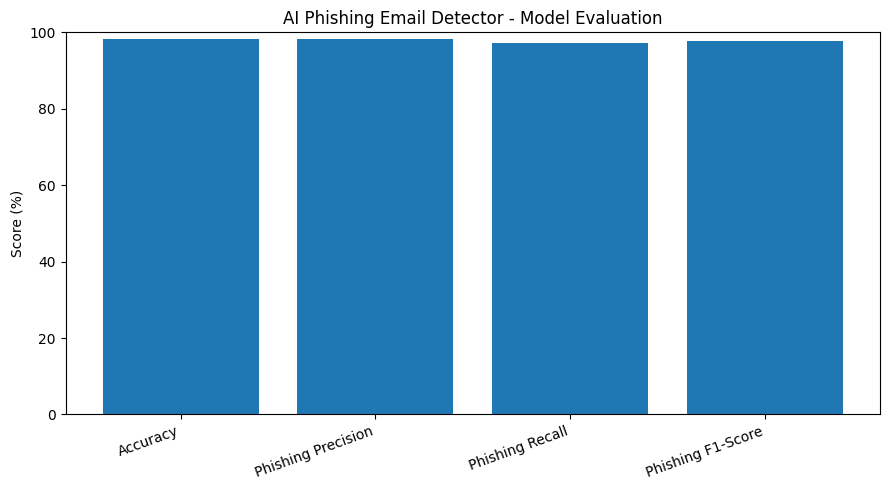

In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import matplotlib.pyplot as plt

# Predict on the existing test dataset
y_pred = model.predict(X_test)

# Calculate phishing-specific metrics
phishing_label = "Phishing Email"

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred,
    pos_label=phishing_label,
    zero_division=0
)
recall = recall_score(
    y_test, y_pred,
    pos_label=phishing_label,
    zero_division=0
)
f1 = f1_score(
    y_test, y_pred,
    pos_label=phishing_label,
    zero_division=0
)

metrics_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Phishing Precision",
        "Phishing Recall",
        "Phishing F1-Score"
    ],
    "Score (%)": [
        round(accuracy * 100, 2),
        round(precision * 100, 2),
        round(recall * 100, 2),
        round(f1 * 100, 2)
    ]
})

display(metrics_df)

# Plot the evaluation metrics
plt.figure(figsize=(9, 5))
plt.bar(metrics_df["Metric"], metrics_df["Score (%)"])
plt.ylim(0, 100)
plt.ylabel("Score (%)")
plt.title("AI Phishing Email Detector - Model Evaluation")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [28]:
import os
import joblib
import json

# Create a folder for project outputs
os.makedirs("phishing_detector_outputs", exist_ok=True)

# 1. Save the trained model
joblib.dump(
    model,
    "phishing_detector_outputs/phishing_detector_model.joblib"
)

# 2. Save batch analysis results
results_df.to_csv(
    "phishing_detector_outputs/batch_analysis_results.csv",
    index=False
)

# 3. Save model evaluation metrics
metrics_df.to_csv(
    "phishing_detector_outputs/model_evaluation_metrics.csv",
    index=False
)

# 4. Save project information
project_info = {
    "project_name": "AI Phishing Email Detector",
    "model": "TF-IDF + Logistic Regression",
    "dataset_rows_after_cleaning": int(len(model_df)),
    "training_samples": int(len(X_train)),
    "testing_samples": int(len(X_test)),
    "accuracy_percent": round(float(accuracy) * 100, 2),
    "phishing_precision_percent": round(float(precision) * 100, 2),
    "phishing_recall_percent": round(float(recall) * 100, 2),
    "phishing_f1_score_percent": round(float(f1) * 100, 2)
}

with open(
    "phishing_detector_outputs/project_summary.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(project_info, file, indent=4)

print("Project outputs saved successfully!")
print("Files created:")
print(os.listdir("phishing_detector_outputs"))

Project outputs saved successfully!
Files created:
['batch_analysis_results.csv', 'project_summary.json', 'model_evaluation_metrics.csv', 'phishing_detector_model.joblib']


In [29]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [30]:
import os
import shutil

# Create a project folder in Google Drive
drive_folder = (
    "/content/drive/MyDrive/AI_Phishing_Email_Detector"
)

os.makedirs(drive_folder, exist_ok=True)

# Copy the complete output folder to Google Drive
source_folder = "phishing_detector_outputs"

for filename in os.listdir(source_folder):
    source_path = os.path.join(source_folder, filename)
    destination_path = os.path.join(drive_folder, filename)

    shutil.copy2(source_path, destination_path)

print("All project files copied to Google Drive!")
print("Saved files:")

for filename in os.listdir(drive_folder):
    print("-", filename)

All project files copied to Google Drive!
Saved files:
- batch_analysis_results.csv
- project_summary.json
- model_evaluation_metrics.csv
- phishing_detector_model.joblib


In [31]:
readme_content = """
# AI Phishing Email Detector

## Overview
A beginner-friendly cybersecurity project that uses Machine
Learning and Natural Language Processing (NLP) to classify
email text as Safe Email or Phishing Email.

## Problem Statement
Phishing emails can trick people into revealing passwords,
financial information, or one-time passwords (OTPs).
This project explores automated detection of suspicious
email text.

## Technologies Used
- Python
- Pandas
- Scikit-learn
- TF-IDF Vectorization
- Logistic Regression
- Matplotlib
- Google Colab

## How It Works
1. Load and clean the email dataset.
2. Remove missing, duplicate, and placeholder email text.
3. Split data into training and testing sets.
4. Convert email text into numerical features using TF-IDF.
5. Train a Logistic Regression classifier.
6. Predict email categories and estimate phishing scores.
7. Evaluate performance using classification metrics.

## Dataset
The cleaned dataset contains 17,521 email records:
- Safe Email: 10,978
- Phishing Email: 6,543

The data was split into training and testing sets using
an 80/20 stratified split.

## Model
TF-IDF + Logistic Regression

## Evaluation
The initial test-set accuracy was 98.32%.
Phishing recall was approximately 97.17%.

These are dataset-specific results and do not guarantee
the same performance on new, real-world emails.

## Features
- Single-email analysis
- Interactive email input in Google Colab
- Batch email analysis
- Estimated phishing score
- Safety recommendations
- Model evaluation chart

## Limitations
- The model can produce false positives and false negatives.
- A high or low score does not guarantee that an email is safe.
- The current prototype analyzes email text, not full email
  headers, sender authentication, or destination URL behavior.
- Avoid pasting real confidential emails into the demo.

## Future Improvements
- Build a web dashboard.
- Test on an independent, newer dataset.
- Analyze URLs and sender information safely.
- Improve detection of previously unseen phishing patterns.

## Disclaimer
This project is an educational prototype and should not be
used as the sole method of deciding whether an email is safe.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content.strip() + "\n")

print("README.md created successfully!")

README.md created successfully!


In [32]:
import shutil

shutil.copy2(
    "README.md",
    "/content/drive/MyDrive/AI_Phishing_Email_Detector/README.md"
)

print("README.md saved to Google Drive!")

README.md saved to Google Drive!


In [33]:
import shutil

shutil.copy2(
    "README.md",
    "/content/drive/MyDrive/AI_Phishing_Email_Detector/README.md"
)

print("README.md saved to Google Drive!")

README.md saved to Google Drive!


In [35]:
from google.colab import files
files.download("/content/AI_Phishing_Email_Detector.zip")

FileNotFoundError: Cannot find file: /content/AI_Phishing_Email_Detector.zip

In [36]:
import os
import shutil

# Your existing project folder in Google Drive
drive_folder = "/content/drive/MyDrive/AI_Phishing_Email_Detector"

# Check that the folder exists
if not os.path.isdir(drive_folder):
    print("Project folder not found. Please check your Google Drive path.")
else:
    print("Files found in Google Drive:")
    for name in os.listdir(drive_folder):
        print("-", name)

    # Create ZIP in the Colab /content directory
    zip_path = shutil.make_archive(
        "/content/AI_Phishing_Email_Detector",
        "zip",
        root_dir=drive_folder
    )

    print("\nZIP created successfully!")
    print("ZIP path:", zip_path)
    print("File exists:", os.path.exists(zip_path))

Files found in Google Drive:
- batch_analysis_results.csv
- project_summary.json
- model_evaluation_metrics.csv
- phishing_detector_model.joblib
- README.md

ZIP created successfully!
ZIP path: /content/AI_Phishing_Email_Detector.zip
File exists: True


In [37]:
from google.colab import files

files.download("/content/AI_Phishing_Email_Detector.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
import os

zip_path = "/content/AI_Phishing_Email_Detector.zip"

if os.path.exists(zip_path):
    print("ZIP file exists.")
    print(f"File size: {os.path.getsize(zip_path) / 1024:.2f} KB")
else:
    print("ZIP file is not present in the current Colab session.")

ZIP file exists.
File size: 370.34 KB
